PRACTICAL 1: House Prices Prediction & Market Trend Analysis

Dataset Shape: (1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePri

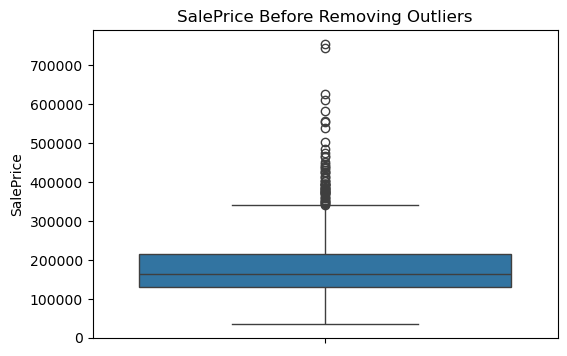

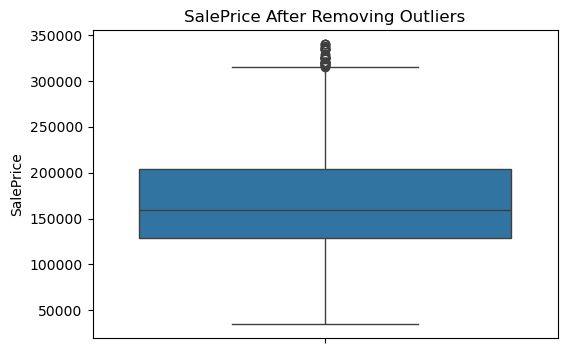


Top 5 Correlated Features
OverallQual    0.784294
GrLivArea      0.661325
GarageCars     0.628013
GarageArea     0.607230
FullBath       0.577369
Name: SalePrice, dtype: float64


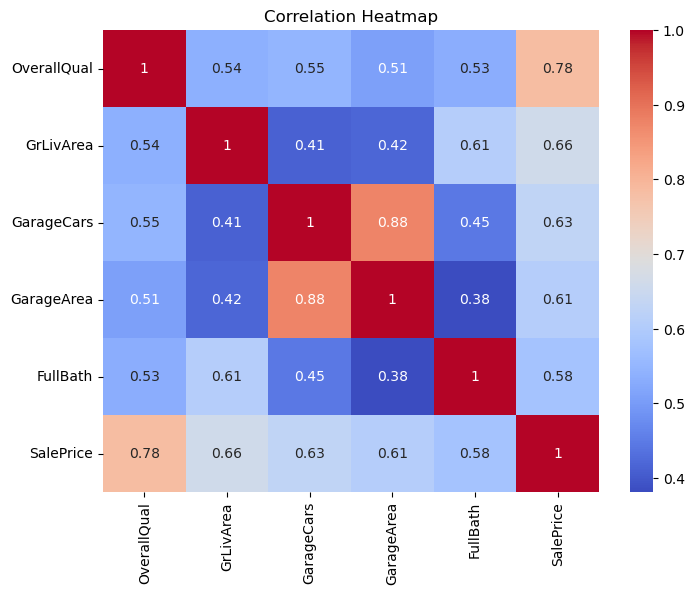

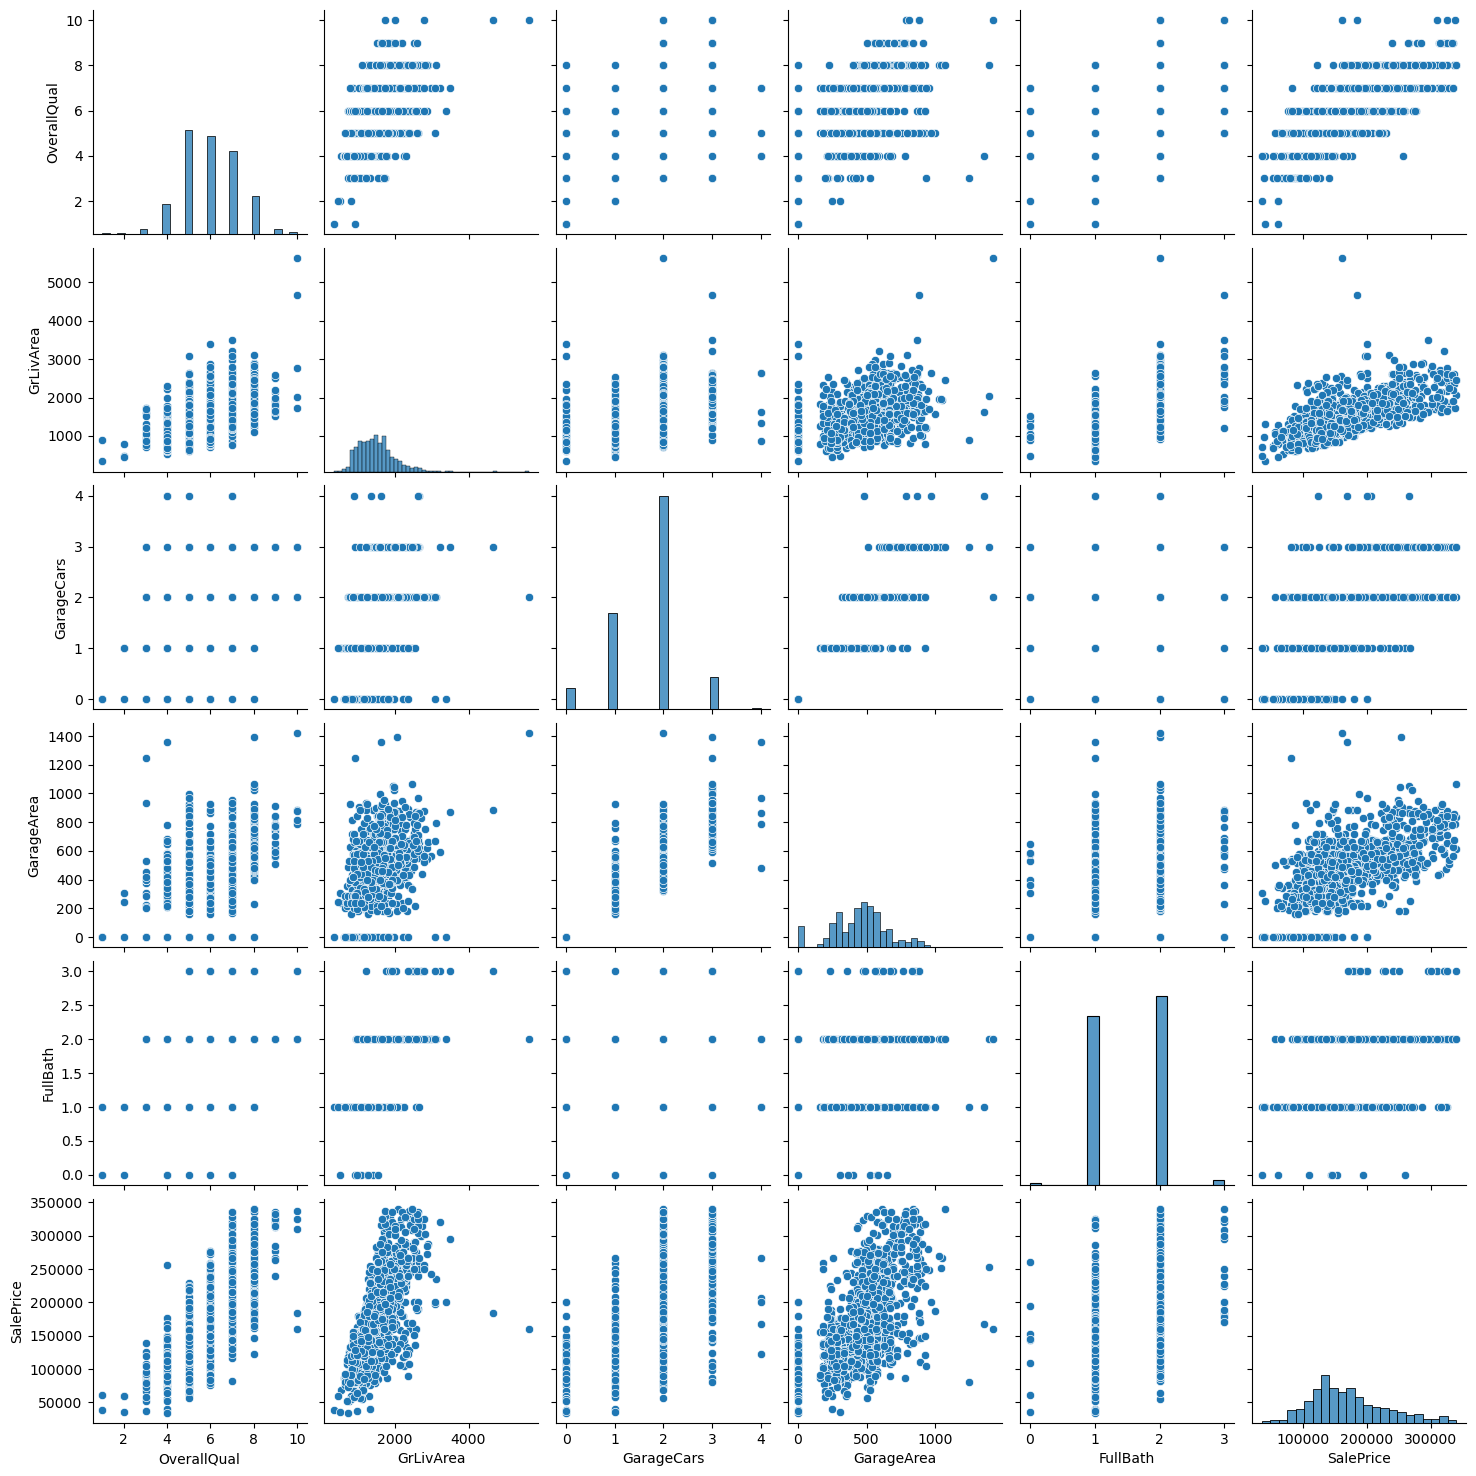

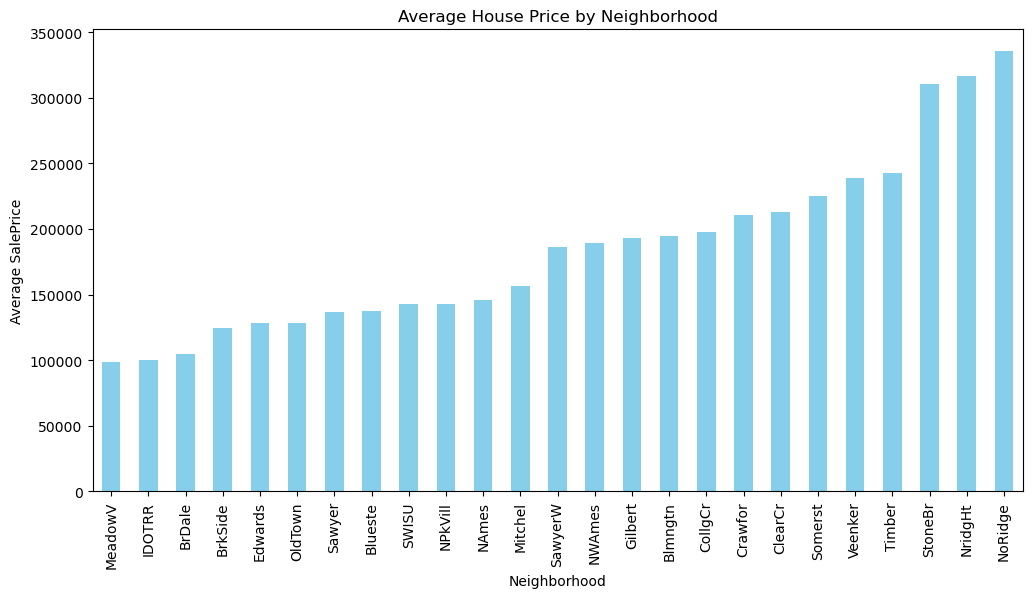


Linear Regression
RMSE: 21895.636337835705
R2 Score: 0.8492780846175607

Decision Tree
RMSE: 31807.73237572453
R2 Score: 0.6819270921780265

KNN Regressor
RMSE: 37308.97287215426
R2 Score: 0.562389385240275

Model Comparison
               Model          RMSE        R2
0  Linear Regression  21895.636338  0.849278
1      Decision Tree  31807.732376  0.681927
2                KNN  37308.972872  0.562389

Best Parameters: {'max_depth': 5, 'min_samples_split': 10}
Best Score: 0.7155102618110722


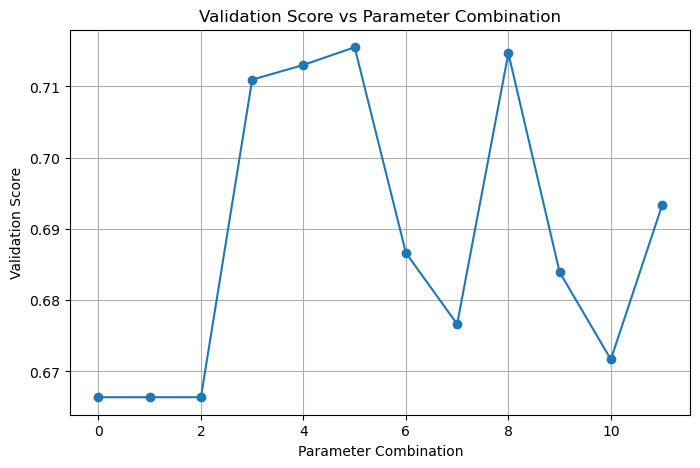

C:\Users\PEARL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


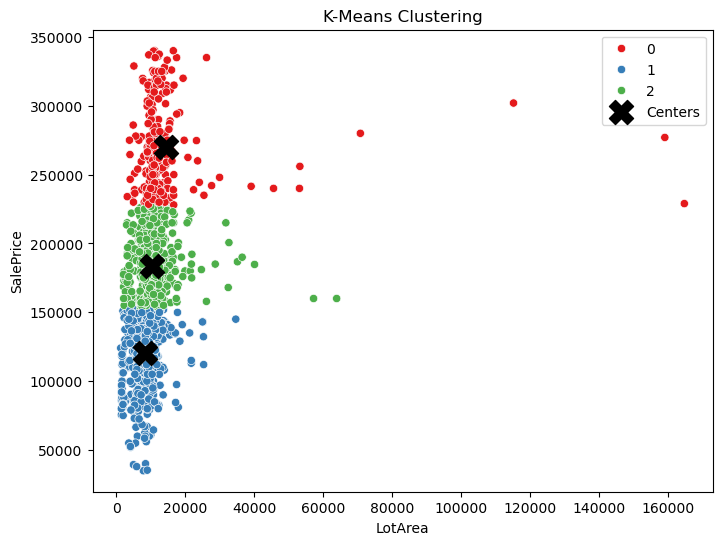


========== FINAL MODEL PERFORMANCE ==========
               Model          RMSE        R2
0  Linear Regression  21895.636338  0.849278
1      Decision Tree  31807.732376  0.681927
2                KNN  37308.972872  0.562389

Best Model: Linear Regression

Practical Completed Successfully.


In [7]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.cluster import KMeans
df = pd.read_csv(r"C:\Users\PEARL\OneDrive\Documents\train.csv")
print("Dataset Shape:", df.shape)
print(df.head())

# 1. Data Cleaning & Preparation

# Missing Values
print("\nMissing Values:")
print(df.isnull().sum())
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print("\nRemaining Missing Values:", df.isnull().sum().sum())

# Encode Categorical Features
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

# Remove Outliers using IQR
plt.figure(figsize=(6,4))
sns.boxplot(y=df["SalePrice"])
plt.title("SalePrice Before Removing Outliers")
plt.show()
Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[(df["SalePrice"] >= lower) & (df["SalePrice"] <= upper)]
plt.figure(figsize=(6,4))
sns.boxplot(y=df["SalePrice"])
plt.title("SalePrice After Removing Outliers")
plt.show()

# 2. Data Analysis & Visualization

corr = df.corr(numeric_only=True)
top5 = corr["SalePrice"].abs().sort_values(ascending=False)[1:6]
print("\nTop 5 Correlated Features")
print(top5)
plt.figure(figsize=(8,6))
sns.heatmap(df[top5.index.tolist()+["SalePrice"]].corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()
sns.pairplot(df[top5.index.tolist()+["SalePrice"]])
plt.show()

# Average SalePrice by Neighborhood
original = pd.read_csv(r"C:\Users\PEARL\OneDrive\Documents\train.csv")
avg_price = original.groupby("Neighborhood")["SalePrice"].mean().sort_values()
plt.figure(figsize=(12,6))
avg_price.plot(kind="bar", color="skyblue")
plt.title("Average House Price by Neighborhood")
plt.ylabel("Average SalePrice")
plt.show()

# 3. Modeling

X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("\nLinear Regression")
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
r2_lr = r2_score(y_test, pred_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)
print("\nDecision Tree")
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)
rmse_dt = np.sqrt(mean_squared_error(y_test, pred_dt))
r2_dt = r2_score(y_test, pred_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)
print("\nKNN Regressor")
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)
rmse_knn = np.sqrt(mean_squared_error(y_test, pred_knn))
r2_knn = r2_score(y_test, pred_knn)
print("RMSE:", rmse_knn)
print("R2 Score:", r2_knn)

# Compare Models
result = pd.DataFrame({
    "Model":["Linear Regression","Decision Tree","KNN"],
    "RMSE":[rmse_lr,rmse_dt,rmse_knn],
    "R2":[r2_lr,r2_dt,r2_knn]
})
print("\nModel Comparison")
print(result)

# 4. GridSearchCV

param_grid = {
    "max_depth":[3,5,10,None],
    "min_samples_split":[2,5,10]
}

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="r2"
)
grid.fit(X_train,y_train)
print("\nBest Parameters:",grid.best_params_)
print("Best Score:",grid.best_score_)
results = pd.DataFrame(grid.cv_results_)
plt.figure(figsize=(8,5))
plt.plot(results["mean_test_score"], marker="o")
plt.title("Validation Score vs Parameter Combination")
plt.xlabel("Parameter Combination")
plt.ylabel("Validation Score")
plt.grid(True)
plt.show()

# 5. KMeans Clustering

cluster_data = df[["LotArea","SalePrice"]]
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kmeans.fit_predict(cluster_data)
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="LotArea",
    y="SalePrice",
    hue="Cluster",
    data=df,
    palette="Set1"
)
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    s=300,
    color="black",
    marker="X",
    label="Centers"
)
plt.title("K-Means Clustering")
plt.legend()
plt.show()

# Final Result
print("\n========== FINAL MODEL PERFORMANCE ==========")
print(result)
best_model = result.loc[result["R2"].idxmax(),"Model"]
print("\nBest Model:",best_model)
print("\nPractical Completed Successfully.")

PRACTICAL 2 Employee Performance Analysis & Attrition Prediction

Dataset Shape: (1470, 35)
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  

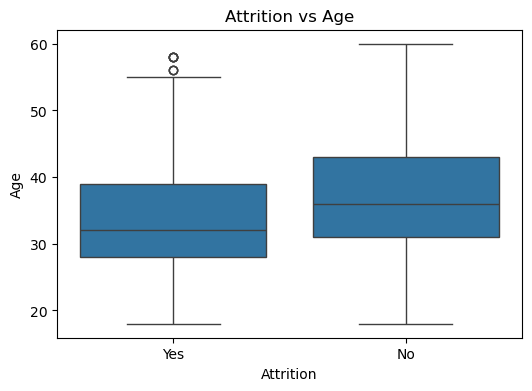

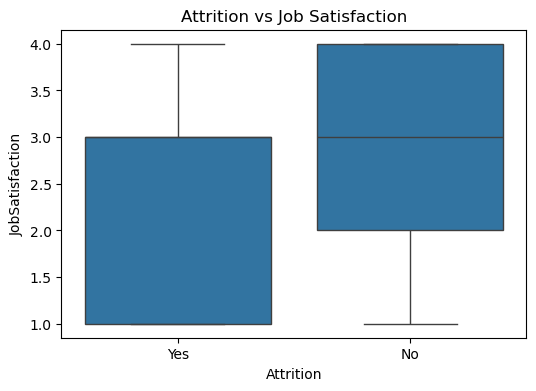

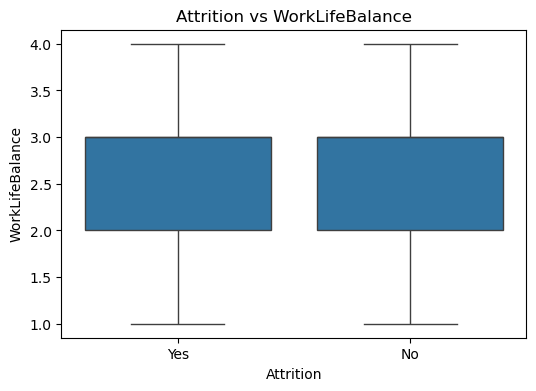

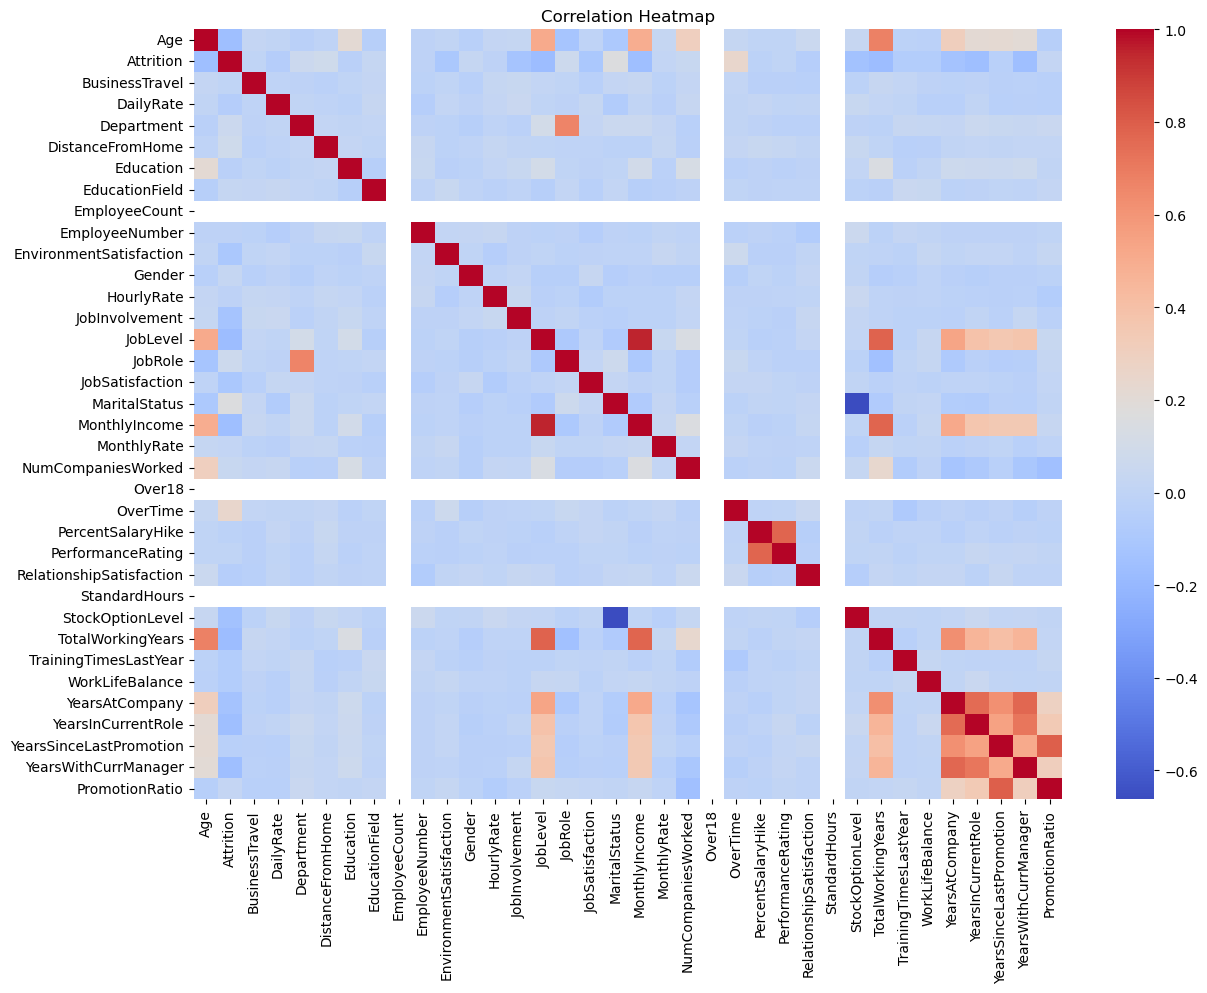


===== Logistic Regression =====
Accuracy : 0.8945578231292517
Precision: 0.7222222222222222
Recall   : 0.3333333333333333
F1 Score : 0.45614035087719296

Confusion Matrix
[[250   5]
 [ 26  13]]

Classification Report
              precision    recall  f1-score   support

           0       0.91      0.98      0.94       255
           1       0.72      0.33      0.46        39

    accuracy                           0.89       294
   macro avg       0.81      0.66      0.70       294
weighted avg       0.88      0.89      0.88       294


===== Decision Tree =====
Accuracy : 0.8061224489795918
Precision: 0.29545454545454547
Recall   : 0.3333333333333333
F1 Score : 0.3132530120481928

===== KNN Classifier =====
Accuracy : 0.8707482993197279
Precision: 0.6
Recall   : 0.07692307692307693
F1 Score : 0.13636363636363635

Model Comparison
                 Model  Accuracy
0  Logistic Regression  0.894558
1        Decision Tree  0.806122
2                  KNN  0.870748


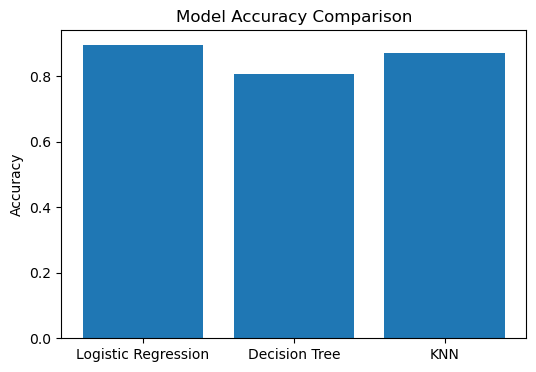


===== GridSearchCV =====
Best Parameters: {'max_depth': 3, 'min_samples_split': 2}
Best CV Score : 0.837573025604039

Cross Validation Scores
[0.8537415  0.84693878 0.8707483  0.84353741 0.8537415 ]


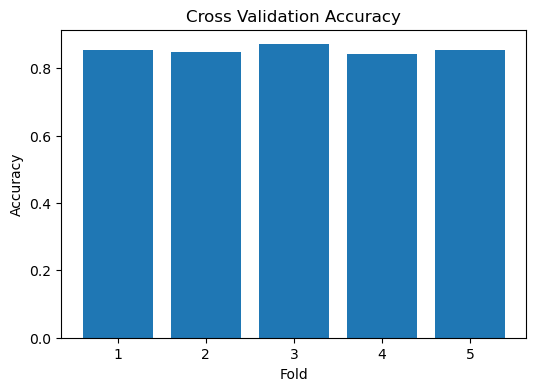

C:\Users\PEARL\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


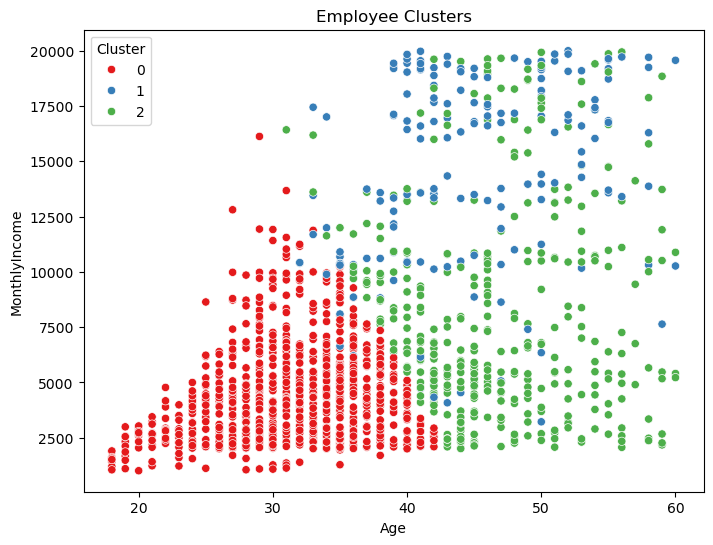


========== FINAL INSIGHTS ==========
1. Employees with low Job Satisfaction tend to leave more frequently.
2. Employees with low Work-Life Balance show higher attrition.
3. Salary growth, promotions and employee engagement can reduce attrition.

========== PRACTICAL COMPLETED ==========


In [9]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
df = pd.read_csv(r"C:\Users\PEARL\OneDrive\Documents\WA_Fn-UseC_-HR-Employee-Attrition.csv")
print("Dataset Shape:", df.shape)
print(df.head())

# Data Cleaning
print("\nMissing Values")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Feature Engineering
df["PromotionRatio"] = (df["YearsSinceLastPromotion"] /(df["TotalWorkingYears"] + 1))

# Label Encoding
cat_cols = df.select_dtypes(include="object").columns
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])
print("\nEncoded Dataset")
print(df.head())

# Exploratory Data Analysis
original = pd.read_csv(r"C:\Users\PEARL\OneDrive\Documents\WA_Fn-UseC_-HR-Employee-Attrition.csv")
print("\nDepartment Attrition Rate")
print(original.groupby("Department")["Attrition"].value_counts(normalize=True))
print("\nAverage Monthly Income by Job Role")
print(original.groupby("JobRole")["MonthlyIncome"].mean())

# Boxplots
plt.figure(figsize=(6,4))
sns.boxplot(x="Attrition", y="Age", data=original)
plt.title("Attrition vs Age")
plt.show()
plt.figure(figsize=(6,4))
sns.boxplot(x="Attrition", y="JobSatisfaction", data=original)
plt.title("Attrition vs Job Satisfaction")
plt.show()
plt.figure(figsize=(6,4))
sns.boxplot(x="Attrition", y="WorkLifeBalance", data=original)
plt.title("Attrition vs WorkLifeBalance")
plt.show()

# Correlation Heatmap
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Prepare Data
X = df.drop("Attrition", axis=1)
y = df["Attrition"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y,test_size=0.2,random_state=42)

# Logistic Regression
print("\n===== Logistic Regression =====")
log = LogisticRegression(max_iter=1000)
log.fit(X_train, y_train)
pred_log = log.predict(X_test)
print("Accuracy :", accuracy_score(y_test, pred_log))
print("Precision:", precision_score(y_test, pred_log))
print("Recall   :", recall_score(y_test, pred_log))
print("F1 Score :", f1_score(y_test, pred_log))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, pred_log))
print("\nClassification Report")
print(classification_report(y_test, pred_log))

# Decision Tree
print("\n===== Decision Tree =====")
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)
print("Accuracy :", accuracy_score(y_test, pred_dt))
print("Precision:", precision_score(y_test, pred_dt))
print("Recall   :", recall_score(y_test, pred_dt))
print("F1 Score :", f1_score(y_test, pred_dt))

# KNN Classifier
print("\n===== KNN Classifier =====")
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)
print("Accuracy :", accuracy_score(y_test, pred_knn))
print("Precision:", precision_score(y_test, pred_knn))
print("Recall   :", recall_score(y_test, pred_knn))
print("F1 Score :", f1_score(y_test, pred_knn))

# Compare Models
result = pd.DataFrame({
    "Model":["Logistic Regression","Decision Tree","KNN"],
    "Accuracy":[
        accuracy_score(y_test,pred_log),
        accuracy_score(y_test,pred_dt),
        accuracy_score(y_test,pred_knn)
    ]
})
print("\nModel Comparison")
print(result)
plt.figure(figsize=(6,4))
plt.bar(result["Model"], result["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()

# GridSearchCV
print("\n===== GridSearchCV =====")
param_grid = {
    "max_depth":[3,5,7,10,None],
    "min_samples_split":[2,5,10]
}
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy"
)
grid.fit(X_train,y_train)
print("Best Parameters:",grid.best_params_)
print("Best CV Score :",grid.best_score_)

# Cross Validation
scores = cross_val_score(grid.best_estimator_,X_scaled,y,cv=5)
print("\nCross Validation Scores")
print(scores)
plt.figure(figsize=(6,4))
plt.bar(range(1,6),scores)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Cross Validation Accuracy")
plt.show()

# KMeans Clustering
cluster_data = df[["Age","MonthlyIncome","YearsAtCompany"]]
cluster_scaled = StandardScaler().fit_transform(cluster_data)
kmeans = KMeans(n_clusters=3,random_state=42)
df["Cluster"] = kmeans.fit_predict(cluster_scaled)
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x="Age",y="MonthlyIncome",hue="Cluster",palette="Set1")
plt.title("Employee Clusters")
plt.show()

# Final Insights
print("\n========== FINAL INSIGHTS ==========")
print("1. Employees with low Job Satisfaction tend to leave more frequently.")
print("2. Employees with low Work-Life Balance show higher attrition.")
print("3. Salary growth, promotions and employee engagement can reduce attrition.")
print("\n========== PRACTICAL COMPLETED ==========")